In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.core.viz.style import apply_style, ITALY_C, EU_C, PEER_C
apply_style()


# Pillar 3 — Local Real Economy, Sectoral Structure & Productivity Proxies: Shift-Share & Firm-Size Decomposition (`2012–2024`)

This notebook examines the productive fabric of **Cesena** (`040007`) against its Emilia-Romagna peers using the **ISTAT ASIA Register of Active Local Units (`Registro statistico delle unità locali delle imprese attive`, `2012–2024`)** across 78 2-digit ATECO 2007 divisions and 7 specialization clusters (`agro_industrial`, `wellness_biomed`, `ict_software`, `tradable_manuf`, `construction_re`, `commerce_hosp`, `business_personal_serv`).

**Methodological Design:**
1. **Endpoint selection before `dropna`:** Following our platform rule (`tests/studies/italy_productivity/test_sectors.py`), every Shift-Share decomposition selects the two compared years (`t0`, `t1`) *before* pivoting/filtering and prints the exact peer count (`n_peers`) and peer list (`peer_ids`).
2. **Exact Classical & Esteban-Marquillas Shift-Share Identity:**
   $$\Delta E_{i} = \text{NS}_{i} + \text{IM}_{i} + \text{CS}_{i}$$
   where $\text{NS}_{i}$ is the Benchmark Share (growth at the peer aggregate employment growth rate, strictly excluding Cesena), $\text{IM}_{i}$ is the Industry Mix effect, and $\text{CS}_{i}$ is the Local Competitive Shift, further decomposed via Esteban-Marquillas (1972) homothetic employment into pure Competitive Advantage (`em_comp_pp`) and Allocative Effect (`em_alloc_pp`).
3. **Exact Bennet Firm-Size Decomposition (`firm_size_decomposition`):** Decomposes the change in municipal average local unit size (`employees / local_units`) between `t0` and `t1` into `mix_effect` (shifts in unit shares across sectors) and `within_scaling_effect` (firm scaling within sectors). Descriptive only.

In [2]:
from cifresignificative.studies.cesena.analysis.data import (
    load_asia, load_asia_size_classes, load_panel_comuni, cesena_vs_peers_series,
    load_frame_sbs_panel, load_frame_sbs_summary,
)
from cifresignificative.studies.cesena.analysis.economy import (
    shift_share, shift_share_all_municipalities, location_quotients,
    firm_size_decomposition, size_class_summary, size_class_by_cluster,
    summarize_frame_sbs_benchmarks, compare_productivity_and_wages,
)

asia = load_asia()
asia_size = load_asia_size_classes()
panel = load_panel_comuni()

print("ASIA municipal 2-digit ATECO dataset coverage (years, municipalities, 2-digit divisions):")
print("Years:", sorted(asia["year"].unique()))
print("Municipalities:", asia["comune_id"].nunique(), "| 2-digit ATECO codes (incl. TOTAL):", asia["ateco_2d"].nunique())

for col, lbl in [
    ("employees", "Total private employees in active local units"),
    ("local_units", "Total active local units"),
    ("avg_firm_size", "Average local unit size (employees / local unit)"),
    ("employees_per_1k_pop", "Private employees per 1,000 residents"),
]:
    s = cesena_vs_peers_series(panel[panel["year"].between(2012, 2024)], col, core_only=True)
    print(f"\n--- {lbl} (2012-2024) ---")
    display(s[["year", "cesena", "core_peer_median", "er_peer_median", "gap_vs_benchmark", "n_core_peers", "missing_core_peers"]].round(2))

ASIA municipal 2-digit ATECO dataset coverage (years, municipalities, 2-digit divisions):
Years: [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Municipalities: 13 | 2-digit ATECO codes (incl. TOTAL): 78

--- Total private employees in active local units (2012-2024) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2012,36760.37,50293.32,50293.32,-13532.94,6,
1,2013,36506.13,49393.64,49393.64,-12887.51,6,
2,2014,36444.61,48643.06,48643.06,-12198.44,6,
3,2015,36439.30,48112.59,48112.59,-11673.29,6,
4,2016,37242.55,48356.22,48356.22,-11113.67,6,
5,2017,37604.19,50466.96,50466.96,-12862.77,6,
6,2018,39077.39,50720.18,50720.18,-11642.79,6,
7,2019,39108.69,55320.36,55320.36,-16211.66,6,
8,2020,37836.06,49119.29,49119.29,-11283.23,6,
9,2021,39114.29,50144.38,50144.38,-11030.08,6,



--- Total active local units (2012-2024) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2012,9600.0,12760.0,12859.0,-3160.0,6,
1,2013,9555.0,12550.5,12690.5,-2995.5,6,
2,2014,9422.0,12296.5,12551.5,-2874.5,6,
3,2015,9336.0,12068.0,12318.5,-2732.0,6,
4,2016,9382.0,12029.5,12330.0,-2647.5,6,
5,2017,9364.0,12086.0,12369.5,-2722.0,6,
6,2018,9399.0,12131.5,12476.0,-2732.5,6,
7,2019,8855.0,11629.0,12124.0,-2774.0,6,
8,2020,9232.0,11946.5,12278.0,-2714.5,6,
9,2021,9445.0,12109.0,12430.5,-2664.0,6,



--- Average local unit size (employees / local unit) (2012-2024) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2012,3.83,3.93,3.92,-0.11,6,
1,2013,3.82,3.93,3.95,-0.11,6,
2,2014,3.87,3.95,3.95,-0.08,6,
3,2015,3.90,3.98,3.98,-0.08,6,
4,2016,3.97,4.01,4.01,-0.04,6,
5,2017,4.02,4.17,4.17,-0.15,6,
6,2018,4.16,4.18,4.18,-0.02,6,
7,2019,4.42,4.57,4.50,-0.15,6,
8,2020,4.10,4.11,4.11,-0.01,6,
9,2021,4.14,4.14,4.13,0.00,6,



--- Private employees per 1,000 residents (2012-2024) ---


,year,cesena,core_peer_median,er_peer_median,gap_vs_benchmark,n_core_peers,missing_core_peers
0,2012,380.41,377.29,392.07,3.12,6,
1,2013,376.62,370.19,383.94,6.43,6,
2,2014,375.69,357.05,370.19,18.64,6,
3,2015,376.89,357.01,370.16,19.88,6,
4,2016,386.01,359.10,376.17,26.91,6,
5,2017,390.31,369.80,385.46,20.51,6,
6,2018,403.96,376.79,390.01,27.17,6,
7,2019,401.44,374.66,402.53,26.78,6,
8,2020,388.20,359.53,380.23,28.67,6,
9,2021,405.25,371.82,389.25,33.42,6,


## 1. Sectoral Specialization & Location Quotients (`LQ`) in Cesena (`2012` vs `2024`)
We compute the Location Quotient ($\text{LQ}_i = (E_{i,c}/E_c) / (E_{i,\text{bench}}/E_{\text{bench}})$) of Cesena relative to the 12 Emilia-Romagna peers (excluding Cesena) first across the 7 specialization clusters and then across the largest 2-digit ATECO divisions.

In [3]:
lq_clust = location_quotients(asia, level="specialization")
lq_12 = lq_clust[lq_clust["year"] == 2012][["specialization", "focal_val", "focal_share_pct", "lq"]].rename(
    columns={"focal_val": "emp_2012", "focal_share_pct": "share_2012_pct", "lq": "lq_2012"}
)
lq_24 = lq_clust[lq_clust["year"] == 2024][["specialization", "sector_label", "focal_val", "focal_share_pct", "bench_share_pct", "lq"]].rename(
    columns={"focal_val": "emp_2024", "focal_share_pct": "share_2024_pct", "lq": "lq_2024"}
)
lq_comp = lq_24.merge(lq_12, on="specialization")
print("Cesena specialization clusters (2012 vs 2024, benchmark = 12 ER peers ex Cesena):")
display(lq_comp[["specialization", "sector_label", "emp_2012", "emp_2024", "share_2012_pct", "share_2024_pct", "bench_share_pct", "lq_2012", "lq_2024"]].round(2))

lq_2d = location_quotients(asia, level="ateco_2d")
lq_2d_24 = lq_2d[lq_2d["year"] == 2024].copy()
lbl_map = dict(zip(asia["ateco_2d"], asia["ateco_label"], strict=False))
lq_2d_24["ateco_label"] = lq_2d_24["ateco_2d"].map(lbl_map)
print("\nTop 15 2-digit ATECO divisions in Cesena by employment (2024, with LQ vs 12 ER peers):")
display(lq_2d_24.sort_values("focal_val", ascending=False).head(15)[["ateco_2d", "ateco_label", "focal_val", "focal_share_pct", "bench_share_pct", "lq"]].round(2))
print("\nTop 10 high-specialization 2-digit ATECO divisions in Cesena (LQ > 1.25 and >= 250 employees in 2024):")
display(lq_2d_24[(lq_2d_24["focal_val"] >= 250) & (lq_2d_24["lq"] > 1.25)].sort_values("lq", ascending=False).head(10)[["ateco_2d", "ateco_label", "focal_val", "focal_share_pct", "bench_share_pct", "lq"]].round(2))

Cesena specialization clusters (2012 vs 2024, benchmark = 12 ER peers ex Cesena):


,specialization,sector_label,emp_2012,emp_2024,share_2012_pct,share_2024_pct,bench_share_pct,lq_2012,lq_2024
0,agro_industrial,Agro-industrial & food machinery,4103.10,5763.83,11.16,13.66,6.25,1.71,2.18
1,wellness_biomed,"Wellness, biomedical & sports",1725.08,2844.61,4.69,6.74,5.75,0.90,1.17
2,construction_re,Construction & real estate,4827.46,4110.79,13.13,9.74,8.42,1.37,1.16
3,tradable_manuf,Other tradable manufacturing,3776.06,4721.35,10.27,11.19,11.04,0.83,1.01
4,commerce_hospitality,"Commerce, tourism & hospitality",11593.01,10825.45,31.54,25.66,25.62,1.16,1.00
5,ict_software,"ICT, software & digital services",775.95,1299.29,2.11,3.08,3.92,0.60,0.78
6,services_other,"Professional, financial & other services",9959.71,12626.70,27.09,29.93,39.00,0.76,0.77



Top 15 2-digit ATECO divisions in Cesena by employment (2024, with LQ vs 12 ER peers):


,ateco_2d,ateco_label,focal_val,focal_share_pct,bench_share_pct,lq
845,10,Food products,4251.94,10.08,2.27,4.44
853,46,Wholesale trade,3702.11,8.77,5.61,1.56
875,47,Retail trade,3343.51,7.92,8.67,0.91
886,56,Food & beverage service,2371.98,5.62,7.60,0.74
867,43,Specialized construction,2056.33,4.87,4.58,1.06
868,78,ATECO 78,1983.59,4.70,4.46,1.05
869,86,Human health activities,1498.29,3.55,3.56,1.00
874,28,Machinery & equipment n.e.c.,1494.46,3.54,3.87,0.91
858,25,Fabricated metal products,1422.28,3.37,2.33,1.45
864,49,Land transport,1415.55,3.36,2.71,1.24



Top 10 high-specialization 2-digit ATECO divisions in Cesena (LQ > 1.25 and >= 250 employees in 2024):


,ateco_2d,ateco_label,focal_val,focal_share_pct,bench_share_pct,lq
845,10,Food products,4251.94,10.08,2.27,4.44
846,32,Other manufacturing (incl. medical/wellness),961.38,2.28,0.55,4.16
848,22,ATECO 22,372.39,0.88,0.46,1.93
851,33,Repair & installation of machinery,561.58,1.33,0.78,1.70
853,46,Wholesale trade,3702.11,8.77,5.61,1.56
854,35,ATECO 35,313.65,0.74,0.48,1.56
856,42,Civil engineering,264.32,0.63,0.42,1.48
858,25,Fabricated metal products,1422.28,3.37,2.33,1.45
861,45,Motor vehicle trade/repair,1246.82,2.96,2.29,1.29
862,68,Real estate activities,1035.80,2.45,1.92,1.28


## 2. Classical & Esteban-Marquillas Shift-Share Decomposition (`2012–2019`, `2019–2024`, `2012–2024`)
We run the exact Shift-Share decomposition across three windows:
- **Pre-pandemic expansion (`2012–2019`)**
- **Pandemic & post-pandemic recovery (`2019–2024`)**
- **Full long-run cycle (`2012–2024`)**

Both against the **6 Core Peers** and against **All 12 ER Peers**, at the specialization-cluster level and at the 77 2-digit ATECO division level.

Shift-Share Total Decomposition Summary across Windows, Benchmarks, and Granularities:


,period,benchmark,level,n_peers,emp_t0,emp_t1,delta_abs,cesena_growth_pct,bench_growth_pct,ns_pp,im_pp,cs_pp,active_gap_pp,identity_err_pp
0,2012-2019,Core Peers (6),specialization,6,36760.37,39108.69,2348.32,6.39,7.22,7.22,0.45,-1.29,-0.84,0.0
1,2012-2019,Core Peers (6),ateco_2d,6,36760.37,39108.69,2348.32,6.39,7.29,7.29,-0.17,-0.74,-0.90,0.0
2,2012-2019,All ER Peers (12),specialization,12,36760.37,39108.69,2348.32,6.39,8.62,8.62,-1.23,-1.00,-2.23,0.0
3,2012-2019,All ER Peers (12),ateco_2d,12,36760.37,39108.69,2348.32,6.39,8.61,8.61,-2.88,0.66,-2.22,0.0
4,2019-2024,Core Peers (6),specialization,6,39108.69,42192.02,3083.33,7.88,2.39,2.39,-0.03,5.53,5.50,0.0
5,2019-2024,Core Peers (6),ateco_2d,6,39108.69,42192.02,3083.33,7.88,2.43,2.43,1.86,3.59,5.45,0.0
6,2019-2024,All ER Peers (12),specialization,12,39108.69,42192.02,3083.33,7.88,2.85,2.85,-0.09,5.12,5.04,0.0
7,2019-2024,All ER Peers (12),ateco_2d,12,39108.69,42192.02,3083.33,7.88,2.88,2.88,0.83,4.18,5.01,0.0
8,2012-2024,Core Peers (6),specialization,6,36760.37,42192.02,5431.65,14.78,9.78,9.78,-0.56,5.56,4.99,0.0
9,2012-2024,Core Peers (6),ateco_2d,6,36760.37,42192.02,5431.65,14.78,9.91,9.91,-0.56,5.42,4.87,0.0



Detailed Cluster Shift-Share (2012-2024, vs 6 Core Peers):


,sector,sector_label,v0,v1,delta_abs,local_growth_pct,bench_growth_pct,ns_pp,im_pp,cs_pp,total_contrib_pp,em_comp_pp,em_alloc_pp
0,services_other,"Professional, financial & other services",9959.71,12626.70,2666.99,26.78,24.08,2.65,3.87,0.73,7.26,0.83,-0.10
1,agro_industrial,Agro-industrial & food machinery,4103.10,5763.83,1660.73,40.48,0.82,1.09,-1.00,4.43,4.52,2.67,1.76
2,wellness_biomed,"Wellness, biomedical & sports",1725.08,2844.61,1119.53,64.90,33.58,0.46,1.12,1.47,3.05,1.43,0.04
3,tradable_manuf,Other tradable manufacturing,3776.06,4721.35,945.29,25.03,-3.58,1.00,-1.37,2.94,2.57,4.59,-1.65
4,ict_software,"ICT, software & digital services",775.95,1299.29,523.34,67.45,29.87,0.21,0.42,0.79,1.42,0.83,-0.04
5,construction_re,Construction & real estate,4827.46,4110.79,-716.67,-14.85,-6.74,1.28,-2.17,-1.06,-1.95,-0.94,-0.13
6,commerce_hospitality,"Commerce, tourism & hospitality",11593.01,10825.45,-767.56,-6.62,5.23,3.09,-1.44,-3.74,-2.09,-3.33,-0.40



Top 10 job-creating 2-digit ATECO divisions in Cesena (2012-2024, vs 6 Core Peers):


,sector,sector_label,v0,v1,delta_abs,local_growth_pct,bench_growth_pct,im_pp,cs_pp,total_contrib_pp
0,78,ATECO 78,279.38,1983.59,1704.21,610.00,238.78,1.74,2.82,4.64
1,10,Food products,2691.89,4251.94,1560.05,57.95,11.24,0.10,3.42,4.24
2,25,Fabricated metal products,844.34,1422.28,577.94,68.45,29.20,0.44,0.90,1.57
3,32,Other manufacturing (incl. medical/wellness),470.85,961.38,490.53,104.18,112.64,1.32,-0.11,1.33
4,56,Food & beverage service,1893.98,2371.98,478.00,25.24,33.67,1.22,-0.43,1.30
5,86,Human health activities,1051.36,1498.29,446.93,42.51,22.50,0.36,0.57,1.22
6,62,Software & IT consultancy,481.10,910.14,429.04,89.18,65.61,0.73,0.31,1.17
7,81,ATECO 81,546.42,871.02,324.60,59.40,30.15,0.30,0.43,0.88
8,82,ATECO 82,356.58,654.62,298.04,83.58,32.11,0.22,0.50,0.81
9,33,Repair & installation of machinery,349.87,561.58,211.71,60.51,-16.98,-0.26,0.74,0.58



Bottom 8 job-shedding 2-digit ATECO divisions in Cesena (2012-2024, vs 6 Core Peers):


,sector,sector_label,v0,v1,delta_abs,local_growth_pct,bench_growth_pct,im_pp,cs_pp,total_contrib_pp
72,46,Wholesale trade,4758.41,3702.11,-1056.30,-22.20,-13.90,-3.08,-1.07,-2.87
71,43,Specialized construction,2618.29,2056.33,-561.96,-21.46,3.99,-0.42,-1.81,-1.53
70,64,Financial services,1147.61,946.17,-201.44,-17.55,-9.09,-0.59,-0.26,-0.55
69,47,Retail trade,3535.89,3343.51,-192.38,-5.44,1.92,-0.77,-0.71,-0.52
68,68,Real estate activities,1202.63,1035.80,-166.83,-13.87,-10.50,-0.67,-0.11,-0.45
67,23,ATECO 23,287.29,131.21,-156.08,-54.33,-27.81,-0.29,-0.21,-0.42
66,13,ATECO 13,90.26,15.75,-74.51,-82.55,-28.95,-0.10,-0.13,-0.20
65,49,Land transport,1485.36,1415.55,-69.81,-4.70,13.75,0.16,-0.75,-0.19



Leave-one-out Shift-Share Ranking across all 13 ER Municipalities (2012-2024, sorted by Competitive Shift cs_total_pp):


,cs_rank,focal_name,v0_total,v1_total,delta_total_abs,local_growth_total_pct,bench_growth_total_pct,ns_total_pp,im_total_pp,cs_total_pp,active_gap_pp
0,1,Cesena,36760.37,42192.02,5431.65,14.78,11.71,11.71,-1.86,4.92,3.07
1,2,Reggio nell'Emilia,71006.40,82188.60,11182.20,15.75,11.44,11.44,-0.15,4.45,4.30
2,3,Parma,79846.04,92997.51,13151.47,16.47,11.30,11.30,1.01,4.16,5.17
3,4,Piacenza,41295.75,47588.39,6292.64,15.24,11.66,11.66,0.89,2.68,3.58
4,5,Modena,82686.42,94452.82,11766.40,14.23,11.56,11.56,0.74,1.93,2.67
5,6,Rimini,56239.62,62496.22,6256.60,11.12,11.92,11.92,-1.02,0.22,-0.80
6,7,Forlì,45387.89,49271.30,3883.41,8.56,12.08,12.08,-2.77,-0.76,-3.53
7,8,Carpi,24121.54,25868.93,1747.39,7.24,12.02,12.02,-3.63,-1.15,-4.78
8,9,Faenza,21820.37,23748.93,1928.56,8.84,11.96,11.96,-1.47,-1.64,-3.12
9,10,Imola,25096.50,26907.40,1810.90,7.22,12.03,12.03,-2.07,-2.74,-4.81


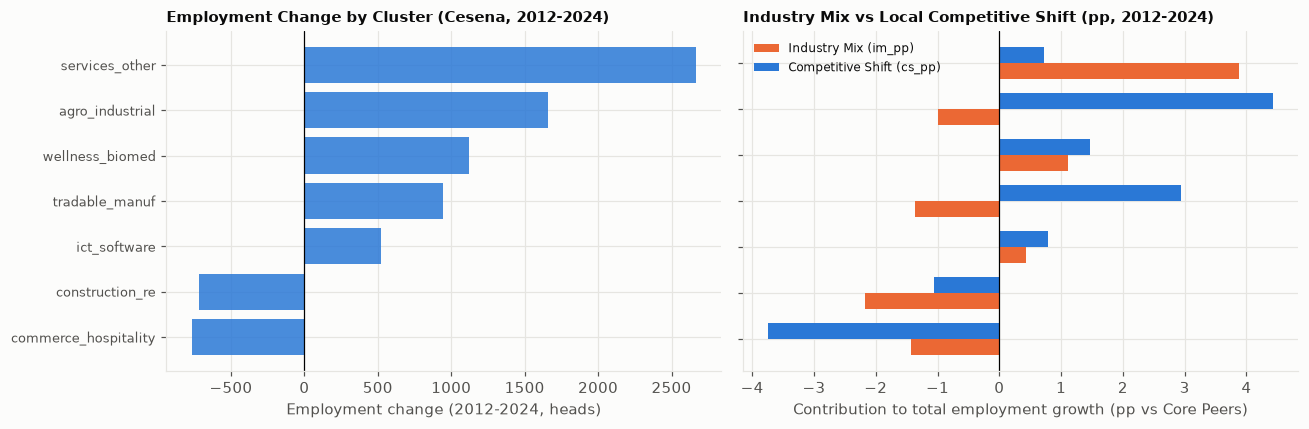

In [4]:
summary_rows = []
for (t0, t1) in [(2012, 2019), (2019, 2024), (2012, 2024)]:
    for core_flag, bench_lbl in [(True, "Core Peers (6)"), (False, "All ER Peers (12)")]:
        for lvl in ["specialization", "ateco_2d"]:
            df_ss, s = shift_share(asia, t0=t0, t1=t1, level=lvl, core_only=core_flag)
            summary_rows.append({
                "period": f"{t0}-{t1}",
                "benchmark": bench_lbl,
                "level": lvl,
                "n_peers": s["n_peers"],
                "emp_t0": s["v0_total"],
                "emp_t1": s["v1_total"],
                "delta_abs": s["delta_total_abs"],
                "cesena_growth_pct": s["local_growth_total_pct"],
                "bench_growth_pct": s["bench_growth_total_pct"],
                "ns_pp": s["ns_total_pp"],
                "im_pp": s["im_total_pp"],
                "cs_pp": s["cs_total_pp"],
                "active_gap_pp": s["active_gap_pp"],
                "identity_err_pp": abs(s["local_growth_total_pct"] - (s["ns_total_pp"] + s["im_total_pp"] + s["cs_total_pp"])),
            })

ss_sum_df = pd.DataFrame(summary_rows)
print("Shift-Share Total Decomposition Summary across Windows, Benchmarks, and Granularities:")
display(ss_sum_df.round(2))

ss_clust_full, s_clust = shift_share(asia, t0=2012, t1=2024, level="specialization", core_only=True)
print("\nDetailed Cluster Shift-Share (2012-2024, vs 6 Core Peers):")
display(ss_clust_full[[
    "sector", "sector_label", "v0", "v1", "delta_abs", "local_growth_pct", "bench_growth_pct",
    "ns_pp", "im_pp", "cs_pp", "total_contrib_pp", "em_comp_pp", "em_alloc_pp",
]].round(2))

ss_2d_full, _ = shift_share(asia, t0=2012, t1=2024, level="ateco_2d", core_only=True)
print("\nTop 10 job-creating 2-digit ATECO divisions in Cesena (2012-2024, vs 6 Core Peers):")
display(ss_2d_full.sort_values("delta_abs", ascending=False).head(10)[[
    "sector", "sector_label", "v0", "v1", "delta_abs", "local_growth_pct", "bench_growth_pct", "im_pp", "cs_pp", "total_contrib_pp"
]].round(2))
print("\nBottom 8 job-shedding 2-digit ATECO divisions in Cesena (2012-2024, vs 6 Core Peers):")
display(ss_2d_full.sort_values("delta_abs", ascending=True).head(8)[[
    "sector", "sector_label", "v0", "v1", "delta_abs", "local_growth_pct", "bench_growth_pct", "im_pp", "cs_pp", "total_contrib_pp"
]].round(2))

all_muni_ss = shift_share_all_municipalities(asia, t0=2012, t1=2024, level="specialization")
print("\nLeave-one-out Shift-Share Ranking across all 13 ER Municipalities (2012-2024, sorted by Competitive Shift cs_total_pp):")
display(all_muni_ss[[
    "cs_rank", "focal_name", "v0_total", "v1_total", "delta_total_abs",
    "local_growth_total_pct", "bench_growth_total_pct", "ns_total_pp", "im_total_pp", "cs_total_pp", "active_gap_pp"
]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))
c_plot = ss_clust_full.sort_values("delta_abs")
y = np.arange(len(c_plot))
axes[0].barh(y, c_plot["delta_abs"], color=ITALY_C, alpha=0.85, label="Actual change (emp.)")
axes[0].set_yticks(y, c_plot["sector"], fontsize=8.5)
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_xlabel("Employment change (2012-2024, heads)")
axes[0].set_title("Employment Change by Cluster (Cesena, 2012-2024)", fontsize=9.5)

axes[1].barh(y - 0.18, c_plot["im_pp"], height=0.35, color=EU_C, label="Industry Mix (im_pp)")
axes[1].barh(y + 0.18, c_plot["cs_pp"], height=0.35, color=ITALY_C, label="Competitive Shift (cs_pp)")
axes[1].set_yticks(y, ["" for _ in c_plot["sector"]])
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_xlabel("Contribution to total employment growth (pp vs Core Peers)")
axes[1].set_title("Industry Mix vs Local Competitive Shift (pp, 2012-2024)", fontsize=9.5)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Exact Bennet Decomposition of Average Local Unit Size (`employees / local_units`, `2012–2024`)
How much of each municipality's change in average local unit size between `2012` and `2024` comes from shifts in sector unit shares (`mix_effect`) versus within-sector firm scaling (`within_scaling_effect`)?

In [5]:
fs_df = firm_size_decomposition(asia, t0=2012, t1=2024)
print("Exact Bennet Decomposition of Change in Average Local Unit Size (2012-2024) across all 13 ER Municipalities:")
display(fs_df[[
    "comune", "units_t0", "units_t1", "units_growth_pct",
    "employees_t0", "employees_t1", "employees_growth_pct",
    "avg_size_t0", "avg_size_t1", "delta_avg_size", "mix_effect", "within_scaling_effect",
]].round(3))

Exact Bennet Decomposition of Change in Average Local Unit Size (2012-2024) across all 13 ER Municipalities:


,comune,units_t0,units_t1,units_growth_pct,employees_t0,employees_t1,employees_growth_pct,avg_size_t0,avg_size_t1,delta_avg_size,mix_effect,within_scaling_effect
0,Cesena,9600.0,9736.0,1.417,36760.37,42192.02,14.776,3.829,4.334,0.504,-0.164,0.668
1,Piacenza,11144.0,11430.0,2.566,41295.75,47588.39,15.238,3.706,4.163,0.458,0.007,0.451
2,Reggio nell'Emilia,17482.0,18292.0,4.633,71006.40,82188.60,15.748,4.062,4.493,0.431,-0.203,0.634
3,Forlì,11815.0,11568.0,-2.091,45387.89,49271.30,8.556,3.842,4.259,0.418,-0.107,0.525
4,Parma,20002.0,21477.0,7.374,79846.04,92997.51,16.471,3.992,4.330,0.338,-0.097,0.435
5,Modena,19383.0,20960.0,8.136,82686.42,94452.82,14.230,4.266,4.506,0.240,-0.154,0.394
6,Ravenna,13705.0,13460.0,-1.788,55198.74,57423.30,4.030,4.028,4.266,0.239,-0.059,0.298
7,Faenza,5240.0,5395.0,2.958,21820.37,23748.93,8.838,4.164,4.402,0.238,-0.228,0.466
8,Rimini,17363.0,17990.0,3.611,56239.62,62496.22,11.125,3.239,3.474,0.235,-0.053,0.288
9,Ferrara,12013.0,12179.0,1.382,40726.69,43495.25,6.798,3.390,3.571,0.181,-0.133,0.314


## 4. Employment Size-Class Decomposition (`W0_9`, `W10_49`, `W50_249`, `W_GE250`, `2012–2024`)
Does Cesena's `#1` within-sector firm-size scaling reflect a consolidation of micro-units (`0–9` workers) into small and medium-sized enterprises (`10–49` and `50–249` workers), or employment concentration inside large anchor plants (`250+` workers)? We decompose `asia_size_classes.parquet` across the four ISTAT ASIA employment size classes and across specialization clusters $\times$ size classes.

In [6]:
sc_class, sc_muni = size_class_summary(asia_size, t0=2012, t1=2024, core_only=True)
print("Cesena vs 6 Core Peers by Employment Size Class (2012-2024):")
display(sc_class[[
    "size_class", "size_label", "units_t0", "units_t1", "delta_units", "units_growth_pct",
    "emp_t0", "emp_t1", "delta_emp", "emp_growth_pct", "bench_emp_growth_pct",
    "emp_share_t0_pct", "emp_share_t1_pct", "bench_emp_share_t1_pct",
    "contrib_to_total_growth_pp", "bench_contrib_to_total_growth_pp",
]].round(2))

print("\nAll 13 ER Municipalities — Employment Growth Contributions (pp) by Size Class (2012-2024, ranked by Medium 50-249 contribution):")
display(sc_muni[[
    "rank_W50_249_contrib", "comune", "emp_growth_pct",
    "contrib_W0_9_pp", "contrib_W10_49_pp", "contrib_W50_249_pp", "contrib_W_GE250_pp",
    "share_W0_9_t0_pct", "share_W0_9_t1_pct", "delta_units_W50_249", "delta_units_W_GE250",
]].round(2))

sc_clust = size_class_by_cluster(asia_size, t0=2012, t1=2024)
print("\nCesena Specialization Cluster x Size Class Employment Change (2012-2024):")
display(sc_clust[[
    "specialization", "specialization_label",
    "delta_W0_9", "delta_W10_49", "delta_W50_249", "delta_W_GE250", "delta_total",
    "emp_W0_9_2024", "emp_W10_49_2024", "emp_W50_249_2024", "emp_W_GE250_2024", "emp_total_t1",
]].round(2))

Cesena vs 6 Core Peers by Employment Size Class (2012-2024):


,size_class,size_label,units_t0,units_t1,delta_units,units_growth_pct,emp_t0,emp_t1,delta_emp,emp_growth_pct,bench_emp_growth_pct,emp_share_t0_pct,emp_share_t1_pct,bench_emp_share_t1_pct,contrib_to_total_growth_pp,bench_contrib_to_total_growth_pp
0,W0_9,Micro (0-9 employees),8978.0,9026.0,48.0,0.53,17134.87,15784.60,-1350.27,-7.88,-7.88,46.61,37.41,40.30,-3.67,-3.79
1,W10_49,Small (10-49 employees),555.0,611.0,56.0,10.09,10055.53,11686.90,1631.37,16.22,16.63,27.35,27.70,27.33,4.44,4.28
2,W50_249,Medium (50-249 employees),57.0,89.0,32.0,56.14,4777.87,8453.69,3675.82,76.93,47.87,13.00,20.04,21.50,10.00,7.64
3,W_GE250,Large (250+ employees),10.0,10.0,0.0,0.00,4792.10,6266.83,1474.73,30.77,16.06,13.04,14.85,10.86,4.01,1.65



All 13 ER Municipalities — Employment Growth Contributions (pp) by Size Class (2012-2024, ranked by Medium 50-249 contribution):


,rank_W50_249_contrib,comune,emp_growth_pct,contrib_W0_9_pp,contrib_W10_49_pp,contrib_W50_249_pp,contrib_W_GE250_pp,share_W0_9_t0_pct,share_W0_9_t1_pct,delta_units_W50_249,delta_units_W_GE250
0,1,Imola,7.22,-1.04,1.37,11.00,-4.11,40.63,36.93,23.0,-4.0
1,2,Cesena,14.78,-3.67,4.44,10.00,4.01,46.61,37.41,32.0,0.0
2,3,Parma,16.47,-1.00,3.32,9.11,5.05,42.94,36.01,71.0,10.0
3,4,Carpi,7.24,-4.64,1.48,8.94,1.47,53.82,45.85,12.0,1.0
4,5,Piacenza,15.24,-2.03,3.82,8.64,4.80,48.31,40.16,38.0,3.0
5,6,Reggio nell'Emilia,15.75,-2.73,3.58,8.43,6.47,42.72,34.55,60.0,8.0
6,7,Forlì,8.56,-5.49,5.36,7.43,1.25,46.71,37.97,36.0,2.0
7,8,Ferrara,6.80,-4.15,1.84,6.90,2.20,51.43,44.27,22.0,1.0
8,9,Rimini,11.12,-4.35,5.62,6.37,3.49,59.48,49.61,37.0,4.0
9,10,Ravenna,4.03,-4.06,5.46,6.01,-3.38,45.15,39.50,24.0,-5.0



Cesena Specialization Cluster x Size Class Employment Change (2012-2024):


,specialization,specialization_label,delta_W0_9,delta_W10_49,delta_W50_249,delta_W_GE250,delta_total,emp_W0_9_2024,emp_W10_49_2024,emp_W50_249_2024,emp_W_GE250_2024,emp_total_t1
0,services_other,"Professional, financial & other services",59.73,585.96,1488.18,533.12,2666.99,5188.25,3179.72,2884.88,1373.85,12626.70
1,agro_industrial,Agro-industrial & food machinery,-124.16,-31.29,462.19,1353.99,1660.73,317.63,645.28,1088.28,3712.64,5763.83
2,wellness_biomed,"Wellness, biomedical & sports",178.82,329.89,105.06,505.76,1119.53,1191.22,446.33,359.76,847.30,2844.61
3,tradable_manuf,Other tradable manufacturing,-169.54,224.48,557.31,333.04,945.29,1002.92,1996.62,1388.77,333.04,4721.35
4,ict_software,"ICT, software & digital services",27.13,210.14,286.07,0.00,523.34,403.38,544.66,351.25,0.00,1299.29
5,construction_re,Construction & real estate,-421.72,83.55,205.25,-583.75,-716.67,2585.30,1019.84,505.65,0.00,4110.79
6,commerce_hospitality,"Commerce, tourism & hospitality",-900.53,228.64,571.76,-667.43,-767.56,5095.90,3854.45,1875.10,0.00,10825.45


## 5. ISTAT FRAME-SBS Territorial Economic Accounts: Value Added, Productivity & Wages (`2017–2023`)
How do **Value Added per worker (`VA / addetto`)** and **salaried wages per employee (`retribuzione / dipendente`)** compare with peers? Employment here shares the 2022 food-sector break seen in ASIA, so ratios per worker are unstable.

We examine the **ISTAT FRAME-SBS Territoriale (`Registro Statistico Esteso dei Conti Economici delle Imprese`, `2017–2023`)** municipal accounts across:
- **Total market economy (`totale`)**
- **Industry (`industria`)**
- **Services (`servizi`)**

FRAME-SBS municipal panel coverage (years, municipalities, macro-sectors):
Years: [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]
Municipalities: 29 | Macro-sectors: ['industria', 'servizi', 'totale']

--- Total Market Economy (Industry + Services): Cesena vs Peers (2017-2023) ---


,year,cesena_addetti,cesena_va_per_addetto_eur,core_peer_va_per_addetto_eur,gap_va_per_addetto_core_pct,rank_va_per_addetto_er,cesena_retrib_per_dipendente_eur,core_peer_retrib_per_dipendente_eur,gap_retrib_per_dipendente_core_pct,rank_retrib_per_dipendente_er,cesena_va_su_fatturato_pct,cesena_retrib_su_va_pct
0,2017,36236.0,47912.30,48621.81,-1.46,7,26794.90,27162.16,-1.35,9,20.8,39.5
1,2018,37772.0,48131.71,48059.80,0.15,8,26597.11,27079.97,-1.78,9,21.4,39.8
2,2019,37763.0,48825.57,46345.49,5.35,5,26601.59,26304.80,1.13,8,20.9,40.0
3,2020,36584.0,48214.96,48554.38,-0.70,7,27126.13,25335.80,7.07,4,21.3,41.2
4,2021,37793.0,52955.60,56905.03,-6.94,9,27430.37,27641.75,-0.76,8,21.3,38.2
5,2022,37120.0,58042.56,55222.02,5.11,6,27506.51,28400.24,-3.15,10,22.6,34.7
6,2023,41315.0,58946.27,60176.65,-2.04,8,28268.08,28968.44,-2.42,9,23.3,36.4



--- Industry (Manufacturing, Mining, Energy, Construction): Cesena vs Peers (2017-2023) ---


,year,cesena_addetti,cesena_va_per_addetto_eur,core_peer_va_per_addetto_eur,gap_va_per_addetto_core_pct,rank_va_per_addetto_er,cesena_retrib_per_dipendente_eur,core_peer_retrib_per_dipendente_eur,gap_retrib_per_dipendente_core_pct,rank_retrib_per_dipendente_er,cesena_va_su_fatturato_pct,cesena_retrib_su_va_pct
0,2017,11996.0,64319.02,63843.68,0.74,9,31496.47,31870.88,-1.17,10,27.7,40.4
1,2018,12419.0,70373.70,65555.23,7.35,9,31519.94,32103.50,-1.82,10,28.5,37.4
2,2019,12945.0,68223.64,64833.10,5.23,8,31144.04,31850.73,-2.22,11,27.5,38.9
3,2020,12439.0,71028.70,61641.90,15.23,6,34323.89,30320.14,13.20,5,26.8,41.4
4,2021,13192.0,77308.52,74572.29,3.67,9,32765.50,33459.86,-2.08,9,27.4,36.6
5,2022,11751.0,90980.09,71529.80,27.19,5,33876.22,34056.38,-0.53,10,24.3,31.6
6,2023,15474.0,82774.72,82419.00,0.43,9,33195.33,35052.07,-5.30,11,25.4,35.3



--- Market Services (Commerce, Transport, Tourism, ICT, Business/Personal Services): Cesena vs Peers (2017-2023) ---


,year,cesena_addetti,cesena_va_per_addetto_eur,core_peer_va_per_addetto_eur,gap_va_per_addetto_core_pct,rank_va_per_addetto_er,cesena_retrib_per_dipendente_eur,core_peer_retrib_per_dipendente_eur,gap_retrib_per_dipendente_core_pct,rank_retrib_per_dipendente_er,cesena_va_su_fatturato_pct,cesena_retrib_su_va_pct
0,2017,24240.0,39792.82,39314.96,1.22,6,23823.18,23835.91,-0.05,7,17.3,38.7
1,2018,25354.0,37235.11,39844.99,-6.55,11,23568.37,23647.75,-0.34,8,17.4,42.0
2,2019,24819.0,38706.03,38503.84,0.53,8,23606.89,23504.98,0.43,7,17.1,41.1
3,2020,24144.0,36463.30,37797.82,-3.53,8,22383.77,22243.23,0.63,8,17.6,41.1
4,2021,24601.0,39896.63,43460.68,-8.20,11,23735.70,24174.29,-1.81,9,17.3,39.8
5,2022,25368.0,42787.49,45969.97,-6.92,10,23825.12,24507.53,-2.78,11,21.1,37.8
6,2023,25841.0,44677.41,48377.63,-7.65,10,24479.29,24938.80,-1.84,10,21.3,37.6



Cumulative Real Growth across all 13 ER Municipalities (Total Market Economy, 2017-2023):


,comune_nome,growth_addetti_pct,rank_growth_addetti,growth_real_va_pct,rank_growth_real_va,growth_real_vap_pct,rank_growth_real_vap,growth_real_wage_pct,rank_growth_real_wage
0,Imola,7.67,6,28.31,1,19.17,1,-9.42,8
1,Cesena,14.02,1,17.58,2,3.13,6,-11.57,11
2,Forlì,7.94,5,17.49,3,8.84,3,-6.53,2
3,Parma,4.33,10,17.18,4,12.31,2,-6.56,3
4,Reggio nell'Emilia,8.17,4,14.82,5,6.15,4,-7.86,6
5,Piacenza,7.38,7,12.83,6,5.07,5,-8.14,7
6,Rimini,9.98,2,12.44,7,2.24,9,-7.50,5
7,Faenza,6.75,8,9.32,8,2.41,8,-7.22,4
8,Carpi,5.03,9,4.89,9,-0.13,11,-13.45,13
9,Bologna,1.66,12,4.36,10,2.66,7,-6.01,1



Cumulative Real Growth across all 13 ER Municipalities (Industry, 2017-2023):


,comune_nome,growth_addetti_pct,rank_growth_addetti,growth_real_va_pct,rank_growth_real_va,growth_real_vap_pct,rank_growth_real_vap,growth_real_wage_pct,rank_growth_real_wage
0,Imola,13.50,3,45.17,1,27.90,1,-10.42,7
1,Cesena,28.99,1,39.15,2,7.87,7,-11.66,11
2,Rimini,18.94,2,36.24,3,14.55,5,-3.90,1
3,Parma,13.41,4,31.04,4,15.54,3,-12.77,12
4,Piacenza,10.51,7,27.53,5,15.41,4,-8.56,4
5,Reggio nell'Emilia,10.76,6,25.52,6,13.33,6,-9.38,6
6,Bologna,3.61,12,20.03,7,15.85,2,-10.84,10
7,Forlì,8.80,8,14.95,8,5.65,9,-6.07,2
8,Faenza,5.35,10,8.58,9,3.07,10,-8.43,3
9,Carpi,-1.57,13,5.82,10,7.51,8,-8.61,5


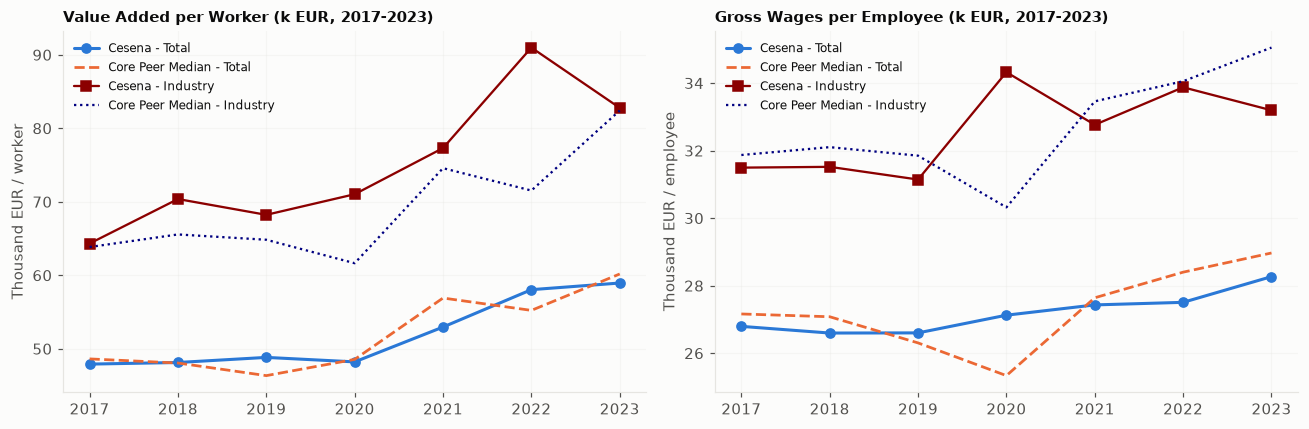

In [7]:
frame_panel = load_frame_sbs_panel()
frame_sum = load_frame_sbs_summary()

print("FRAME-SBS municipal panel coverage (years, municipalities, macro-sectors):")
print("Years:", sorted(frame_panel["year"].unique()))
print("Municipalities:", frame_panel["comune_id"].nunique(), "| Macro-sectors:", sorted(frame_panel["macro_sector"].unique()))

for sec, lbl in [
    ("totale", "Total Market Economy (Industry + Services)"),
    ("industria", "Industry (Manufacturing, Mining, Energy, Construction)"),
    ("servizi", "Market Services (Commerce, Transport, Tourism, ICT, Business/Personal Services)"),
]:
    b = summarize_frame_sbs_benchmarks(frame_panel, sector=sec)
    print(f"\n--- {lbl}: Cesena vs Peers (2017-2023) ---")
    display(b[[
        "year", "cesena_addetti", "cesena_va_per_addetto_eur", "core_peer_va_per_addetto_eur",
        "gap_va_per_addetto_core_pct", "rank_va_per_addetto_er",
        "cesena_retrib_per_dipendente_eur", "core_peer_retrib_per_dipendente_eur",
        "gap_retrib_per_dipendente_core_pct", "rank_retrib_per_dipendente_er",
        "cesena_va_su_fatturato_pct", "cesena_retrib_su_va_pct",
    ]].round(2))

# Cumulative growth comparison 2017-2023
growth_tot = compare_productivity_and_wages(frame_panel, sector="totale", t0=2017, t1=2023)
print("\nCumulative Real Growth across all 13 ER Municipalities (Total Market Economy, 2017-2023):")
display(growth_tot[[
    "comune_nome", "growth_addetti_pct", "rank_growth_addetti",
    "growth_real_va_pct", "rank_growth_real_va",
    "growth_real_vap_pct", "rank_growth_real_vap",
    "growth_real_wage_pct", "rank_growth_real_wage",
]].round(2))

growth_ind = compare_productivity_and_wages(frame_panel, sector="industria", t0=2017, t1=2023)
print("\nCumulative Real Growth across all 13 ER Municipalities (Industry, 2017-2023):")
display(growth_ind[[
    "comune_nome", "growth_addetti_pct", "rank_growth_addetti",
    "growth_real_va_pct", "rank_growth_real_va",
    "growth_real_vap_pct", "rank_growth_real_vap",
    "growth_real_wage_pct", "rank_growth_real_wage",
]].round(2))

# Plot Cesena vs Core Peers labor productivity and wages
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0))
b_tot = summarize_frame_sbs_benchmarks(frame_panel, sector="totale")
b_ind = summarize_frame_sbs_benchmarks(frame_panel, sector="industria")

axes[0].plot(b_tot["year"], b_tot["cesena_va_per_addetto_eur"] / 1000.0, "o-", color=ITALY_C, lw=2, label="Cesena - Total")
axes[0].plot(b_tot["year"], b_tot["core_peer_va_per_addetto_eur"] / 1000.0, "--", color=EU_C, lw=1.8, label="Core Peer Median - Total")
axes[0].plot(b_ind["year"], b_ind["cesena_va_per_addetto_eur"] / 1000.0, "s-", color="darkred", lw=1.5, label="Cesena - Industry")
axes[0].plot(b_ind["year"], b_ind["core_peer_va_per_addetto_eur"] / 1000.0, ":", color="navy", lw=1.5, label="Core Peer Median - Industry")
axes[0].set_title("Value Added per Worker (k EUR, 2017-2023)", fontsize=9.5)
axes[0].set_ylabel("Thousand EUR / worker")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(b_tot["year"], b_tot["cesena_retrib_per_dipendente_eur"] / 1000.0, "o-", color=ITALY_C, lw=2, label="Cesena - Total")
axes[1].plot(b_tot["year"], b_tot["core_peer_retrib_per_dipendente_eur"] / 1000.0, "--", color=EU_C, lw=1.8, label="Core Peer Median - Total")
axes[1].plot(b_ind["year"], b_ind["cesena_retrib_per_dipendente_eur"] / 1000.0, "s-", color="darkred", lw=1.5, label="Cesena - Industry")
axes[1].plot(b_ind["year"], b_ind["core_peer_retrib_per_dipendente_eur"] / 1000.0, ":", color="navy", lw=1.5, label="Core Peer Median - Industry")
axes[1].set_title("Gross Wages per Employee (k EUR, 2017-2023)", fontsize=9.5)
axes[1].set_ylabel("Thousand EUR / employee")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 7. Primary Agriculture (`ATECO A`) & Provincial Export Specialization (Coeweb & 7° Censimento Agricoltura)

Background at province level, not for the city. Any link between these figures and Cesena's food firms is not tested here, and the land data do not cover poultry.
1. **ISTAT 7° Censimento Generale dell'Agricoltura (2020):** land use (SAT and SAU), fruit orchards (`Frutta`), vineyards (`Vite`), and farm size (`<10 ha` to `>=100 ha`) across the 9 Emilia-Romagna provinces.
2. **ISTAT / Coeweb foreign trade (1991–2025):** provincial exports (`ITH58` Forlì-Cesena), trade balance, coverage ratio and top commodities.

Provincial Foreign Trade Performance (2025 Coeweb, across 9 Emilia-Romagna provinces):


,provincia,nuts3,export_eur,import_eur,trade_balance_eur,coverage_ratio_pct,export_share_pct,export_per_capita_eur,balance_per_capita_eur,rank_export,rank_balance
0,Bologna,ITH55,2.040893e+10,1.084160e+10,9.567329e+09,188.25,24.22,20051.89,9399.95,1,2
1,Modena,ITH54,1.828341e+10,6.918999e+09,1.136441e+10,264.25,21.70,25775.79,16021.44,2,1
2,Reggio Emilia,ITH53,1.310428e+10,6.265780e+09,6.838498e+09,209.14,15.55,24784.21,12933.70,3,3
3,Parma,ITH52,1.006449e+10,5.690452e+09,4.374039e+09,176.87,11.95,22096.89,9603.33,4,4
4,Piacenza,ITH51,6.601974e+09,8.349046e+09,-1.747072e+09,79.07,7.84,23066.81,-6104.14,5,9
5,Ravenna,ITH57,5.738360e+09,7.468240e+09,-1.729881e+09,76.84,6.81,14845.95,-4475.45,6,8
6,Forlì-Cesena,ITH58,4.628745e+09,2.588066e+09,2.040678e+09,178.85,5.49,11788.29,5197.11,7,5
7,Rimini,ITH59,2.843867e+09,1.678753e+09,1.165113e+09,169.40,3.38,8348.87,3420.48,8,7
8,Ferrara,ITH56,2.580013e+09,1.205268e+09,1.374745e+09,214.06,3.06,7597.26,4048.15,9,6



Agricultural Land Use Specialization & Farm Fragmentation (7° Censimento Agricoltura 2020):


,provincia,sau_ha,frutta_ha,frutta_share_sau_pct,frutta_share_er_pct,vite_ha,vite_share_sau_pct,under10_ha,under10_share_sau_pct,over100_share_sau_pct
0,Piacenza,112597.57,348.84,0.31,0.65,5009.22,4.45,9486.0,8.42,34.51
1,Parma,117035.56,314.58,0.27,0.59,598.66,0.51,12321.0,10.53,24.34
2,Reggio Emilia,99455.93,695.01,0.70,1.29,8595.84,8.64,10693.0,10.75,24.54
3,Modena,120287.23,7505.85,6.24,13.98,8535.51,7.10,18780.0,15.61,25.14
4,Bologna,176623.98,7737.83,4.38,14.41,6182.17,3.50,6659.0,3.77,37.90
5,Ferrara,177846.74,11085.33,6.23,20.65,537.02,0.30,11411.0,6.42,46.74
6,Ravenna,121399.81,16836.50,13.87,31.36,16247.45,13.38,15261.0,12.57,36.49
7,Forlì-Cesena,84516.48,8621.64,10.20,16.06,7471.41,8.84,16872.0,19.96,25.41
8,Rimini,33125.75,544.86,1.64,1.01,1656.65,5.00,6801.0,20.53,25.82
9,Emilia-Romagna,1042889.05,53690.44,5.15,100.00,54833.93,5.26,125172.0,12.00,33.21


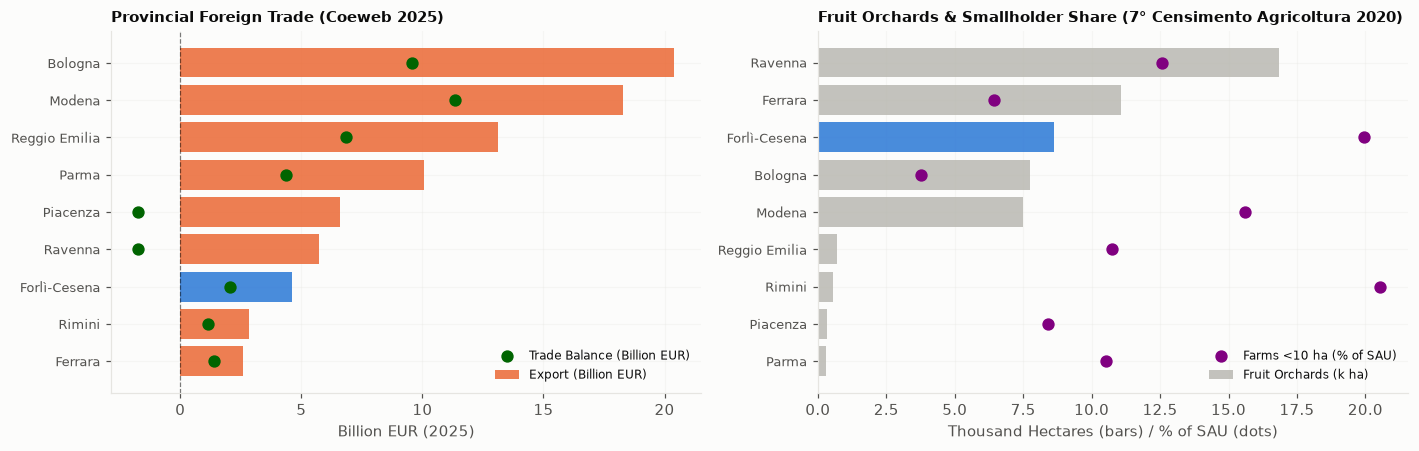

In [8]:
from cifresignificative.studies.cesena.analysis.agri_export import (
    provincial_export_comparison,
    agricultural_land_specialization,
    agroindustrial_cluster_integration,
)

# 1. Provincial Export Comparison (2025)
exp_summary = provincial_export_comparison()
print("Provincial Foreign Trade Performance (2025 Coeweb, across 9 Emilia-Romagna provinces):")
display(exp_summary.provinces_df[[
    "provincia", "nuts3", "export_eur", "import_eur", "trade_balance_eur",
    "coverage_ratio_pct", "export_share_pct", "export_per_capita_eur", "balance_per_capita_eur",
    "rank_export", "rank_balance"
]].round(2))

# 2. Agricultural Land Specialization & Fragmentation (2020 Census)
agri_summary = agricultural_land_specialization()
print("\nAgricultural Land Use Specialization & Farm Fragmentation (7° Censimento Agricoltura 2020):")
display(agri_summary.land_specialization_df[[
    "provincia", "sau_ha", "frutta_ha", "frutta_share_sau_pct", "frutta_share_er_pct",
    "vite_ha", "vite_share_sau_pct", "under10_ha", "under10_share_sau_pct", "over100_share_sau_pct"
]].round(2))

# 3. Dual-Panel Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# Panel 1: Provincial Export & Trade Balance (2025)
df_p = exp_summary.provinces_df.sort_values("export_eur", ascending=True)
y_pos = np.arange(len(df_p))
colors_exp = [ITALY_C if p == "Forlì-Cesena" else EU_C for p in df_p["provincia"]]

axes[0].barh(y_pos, df_p["export_eur"] / 1e9, color=colors_exp, alpha=0.85, label="Export (Billion EUR)")
axes[0].scatter(df_p["trade_balance_eur"] / 1e9, y_pos, color="darkgreen", s=50, zorder=3, label="Trade Balance (Billion EUR)")
axes[0].set_yticks(y_pos, df_p["provincia"], fontsize=8.5)
axes[0].set_xlabel("Billion EUR (2025)")
axes[0].set_title("Provincial Foreign Trade (Coeweb 2025)", fontsize=9.5)
axes[0].axvline(0, color="k", lw=0.8, ls="--", alpha=0.5)
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8, loc="lower right")

# Panel 2: Fruit Orchards Specialization & Smallholder Share
df_ag = agri_summary.land_specialization_df[agri_summary.land_specialization_df["provincia"] != "Emilia-Romagna"].sort_values("frutta_ha", ascending=True)
y_ag = np.arange(len(df_ag))
colors_ag = [ITALY_C if p == "Forlì-Cesena" else PEER_C for p in df_ag["provincia"]]

axes[1].barh(y_ag, df_ag["frutta_ha"] / 1000.0, color=colors_ag, alpha=0.85, label="Fruit Orchards (k ha)")
axes[1].scatter(df_ag["under10_share_sau_pct"], y_ag, color="purple", s=50, zorder=3, label="Farms <10 ha (% of SAU)")
axes[1].set_yticks(y_ag, df_ag["provincia"], fontsize=8.5)
axes[1].set_xlabel("Thousand Hectares (bars) / % of SAU (dots)")
axes[1].set_title("Fruit Orchards & Smallholder Share (7° Censimento Agricoltura 2020)", fontsize=9.5)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.show()

## 8. Register Breaks and Sensitivity (2026-10-30 Review)

ASIA counts persons employed by local unit, so one large unit can move a municipal sector by thousands in a year. The screen flags yearly moves of at least 300 employees and 20% that are mostly undone the next year (`reversal`) or reach 1,000 (`step`). It finds candidates; it does not establish a cause. The sensitivity table shows Cesena's value, rank and peer median with all sectors, without food (ATECO 10), and without food, temp agencies and cleaning (10, 78, 81).

In [9]:
anom = pd.read_parquet("data/processed/cesena/asia_anomalies.parquet")
print(f"Flagged sector-years across the 13 cities: {len(anom)}; by city:")
display(anom.groupby("comune").size().sort_values(ascending=False).to_frame("flagged"))
display(anom[anom["comune_id"] == "040007"].round(2))
sens = pd.read_parquet("data/processed/cesena/employment_sensitivity.parquet")
display(sens.pivot_table(index=["metric", "variant"], columns="t1", values=["cesena", "rank"]).round(2))

# R1: the food break by province and by Cesena size class
from cifresignificative.core.sources import istat_asia
from cifresignificative.studies.cesena.analysis.economy import sector_size_swing
areas = pd.read_parquet("data/processed/cesena/asia_areas.parquet")
food = areas[(areas["ateco_2d"] == "10") & areas["year"].between(2019, 2024)].pivot(index="nuts", columns="year", values="employees")
print("Food manufacturing (ATECO 10) employees by province, ITD5 = region:")
display(food.round(0))
sizes = istat_asia.load_size_classes()
print("Cesena food by size class:")
display(sector_size_swing(sizes, ("10",)).round(2))
print("Cesena temp agencies + cleaning by size class:")
display(sector_size_swing(sizes, ("78", "81"), (2022, 2023, 2024)).round(2))

Flagged sector-years across the 13 cities: 83; by city:


,flagged
comune,
Bologna,17
Parma,17
Modena,16
Reggio nell'Emilia,10
Ravenna,7
Cesena,6
Piacenza,3
Faenza,2
Forlì,2


,comune_id,comune,ateco_2d,year,employees_prev,employees,change,share_undone_next_year,kind
73,040007,Cesena,10,2022,3402.32,1490.21,-1912.11,1.80,reversal
74,040007,Cesena,10,2023,1490.21,4937.65,3447.44,0.20,step
75,040007,Cesena,32,2013,470.85,131.45,-339.40,2.05,reversal
76,040007,Cesena,38,2019,267.34,1079.74,812.40,0.87,reversal
77,040007,Cesena,45,2014,1217.62,1586.83,369.21,1.07,reversal
78,040007,Cesena,52,2013,694.67,1065.39,370.72,1.43,reversal


cesena              rank  \
t1                                                   2021  2022   2024 2021   
metric                variant                                                 
competitive_shift_pp  all_sectors                    3.68 -1.09   5.96  3.0   
                      without_food_10                2.17  3.09   2.74  3.0   
                      without_food_agency_cleaning  -0.85 -0.09  -0.90  7.0   
employment_growth_pct all_sectors                    6.40  4.51  14.78  3.0   
                      without_food_10                4.82  8.39  11.36  5.0   
                      without_food_agency_cleaning   0.35  3.51   5.54  8.0   
unit_size_change      all_sectors                    0.31  0.15   0.50  2.0   
                      without_food_10                0.22  0.27   0.34  4.0   
                      without_food_agency_cleaning   0.09  0.12   0.15  4.0   

                                                              
t1                                                 2022 2024  
metric                variant                                 
competitive_shift_pp  all_sectors                   6.0  1.0  
                      without_food_10               3.0  2.0  
                      without_food_agency_cleaning  7.0  8.0  
employment_growth_pct all_sectors                   9.0  4.0  
                      without_food_10               5.0  7.0  
                      without_food_agency_cleaning  7.0  9.0  
unit_size_change      all_sectors                   6.0  1.0  
                      without_food_10               2.0  4.0  
                      without_food_agency_cleaning  3.0  6.0

Food manufacturing (ATECO 10) employees by province, ITD5 = region:


year,2019,2020,2021,2022,2023,2024
nuts,,,,,,
IT,410142.0,410616.0,417073.0,414652.0,424658.0,433198.0
ITD5,58309.0,58409.0,59175.0,58078.0,62675.0,63832.0
ITH51,3185.0,3199.0,3305.0,3267.0,3264.0,3433.0
ITH52,14738.0,14766.0,14702.0,15102.0,15595.0,15719.0
ITH53,6281.0,6157.0,6383.0,6287.0,6200.0,6702.0
ITH54,9610.0,9671.0,10178.0,11166.0,11108.0,11877.0
ITH55,7231.0,7212.0,6916.0,7097.0,7519.0,6961.0
ITH56,2324.0,2357.0,2566.0,2518.0,2394.0,2564.0
ITH57,5697.0,5696.0,5695.0,5813.0,6112.0,5983.0


Cesena food by size class:


,size_class,emp_2021,emp_2022,emp_2023,emp_2024,lu_2021,lu_2022,lu_2023,lu_2024,delta_2022,share_of_change_2022,delta_2023,share_of_change_2023,delta_2024,share_of_change_2024
0,W0_9,237.75,237.42,220.66,228.27,78.0,76.0,73.0,76.0,-0.33,0.00,-16.76,-0.00,7.61,-0.01
1,W10_49,179.44,134.41,121.16,126.30,8.0,7.0,6.0,5.0,-45.03,0.02,-13.25,-0.00,5.14,-0.01
2,W50_249,408.88,558.77,539.16,512.41,4.0,5.0,5.0,5.0,149.89,-0.08,-19.61,-0.01,-26.75,0.04
3,W_GE250,2576.25,559.61,4056.67,3384.96,2.0,1.0,2.0,3.0,-2016.64,1.05,3497.06,1.01,-671.71,0.98


Cesena temp agencies + cleaning by size class:


,size_class,emp_2022,emp_2023,emp_2024,lu_2022,lu_2023,lu_2024,delta_2023,share_of_change_2023,delta_2024,share_of_change_2024
0,W0_9,244.81,210.42,203.69,117.0,120.0,88.0,-34.39,-0.15,-6.73,-0.06
1,W10_49,439.76,510.98,296.59,20.0,27.0,12.0,71.22,0.31,-214.39,-2.02
2,W50_249,1548.29,1504.29,1336.91,13.0,14.0,12.0,-44.00,-0.19,-167.38,-1.57
3,W_GE250,284.59,522.54,1017.42,1.0,1.0,3.0,237.95,1.03,494.88,4.65


## Takeaways (Pillar 3 — Local Real Economy; Descriptive)

- **Job growth is `sensitive`.** Employment and competitive shift look strong to 2024 but depend on food manufacturing, temp agencies and cleaning, and on the end year. The food series breaks in 2022, at province level too, and the cause is unknown (research track R1).
- **The food break (research track R1) is an `accepted-limit`.** It is local to Forlì-Cesena among the 9 Emilia-Romagna provinces and sits in Cesena's units of 250 or more employees; the cause is unknown and no series is preferred.
- **Larger units are `sensitive` for the same reasons.** Size classes do not track one set of plants: a firm crossing a threshold moves all its jobs, and agency staff are counted at the agency.
- **FRAME-SBS (`sensitive`).** Real value added grew, but value added per worker swings with the same break. "Real" uses consumer prices; values per worker quoted for 2023 are nominal.
- **Agriculture and exports (`context only`).** Province-level background; links to local firms are not tested.
- **Limits.** All statements are descriptive associations for one municipality, never causal claims. The figures are in the table below and in `reports/findings.md`, both computed by `analysis/claims.py`.

In [10]:
from cifresignificative.studies.cesena.analysis.claims import claims_for_notebook

print("Figures behind this notebook, computed from the processed tables (the same ones quoted in reports/findings.md):")
with pd.option_context("display.max_rows", None, "display.max_colwidth", 60):
    display(claims_for_notebook("03"))

Figures behind this notebook, computed from the processed tables (the same ones quoted in reports/findings.md):


,id,text,window,source
0,emp_all_2021,+6.40%,2012-2021,employment_sensitivity.parquet
1,emp_all_2021_rank,#3 of 13,2012-2021,employment_sensitivity.parquet
2,cs_all_2021,+3.68,2012-2021,employment_sensitivity.parquet
3,cs_all_2021_rank,#3 of 13,2012-2021,employment_sensitivity.parquet
4,size_all_2021,+0.31,2012-2021,employment_sensitivity.parquet
5,size_all_2021_rank,#2 of 13,2012-2021,employment_sensitivity.parquet
6,emp_all_2022,+4.51%,2012-2022,employment_sensitivity.parquet
7,emp_all_2022_rank,#9 of 13,2012-2022,employment_sensitivity.parquet
8,cs_all_2022,-1.09,2012-2022,employment_sensitivity.parquet
9,cs_all_2022_rank,#6 of 13,2012-2022,employment_sensitivity.parquet
